# HajjSafe AI — حج امن


### Project Overview

**HajjSafe AI** is an intelligent platform that utilizes artificial intelligence techniques to support pilgrims in making safer and more informed decisions during the Hajj season. The project focuses on verifying suspicious Hajj-related messages and offers, detecting misleading content, and helping users access suitable and reliable campaign options through a simple and trustworthy digital experience




This Notebook is contain only **classification system**
that analyzes Hajj-related messages and classifies them into five categories to protect users from misinformation and fraud.

| Category | Description | Risk Level |
|---|---|---|
| `Official_Info` | Official government messages about permits | Low |
| `Misinformation` | False or misleading information | Medium |
| `Scam_Service` | Fraudulent permit or service offers | High |
| `Violation_Promotion` | Content encouraging regulation violations | High |
| `Suspicious_Link` | Phishing links or suspicious payments | High |

**Approach:** LLM Embeddings (SentenceTransformer) + SVM

---


## 2. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder

# SentenceTransformer
from sentence_transformers import SentenceTransformer

# Plotting style
plt.rcParams['figure.figsize']    = (10, 5)
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['font.size']         = 11

print("All libraries imported successfully.")

All libraries imported successfully.


## 3. Load Dataset

In [ ]:
df = pd.read_csv('Hajj_Data_Final.csv', encoding='utf-8')

print(f"Dataset loaded successfully.")
print(f"Shape : {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Columns: {list(df.columns)}")

Dataset loaded successfully.
Shape : 713 rows x 7 columns
Columns: ['text', 'category', 'risk_level', 'reason', 'recommended_action', 'source_type', 'language']


## 4. Data Understanding

In [ ]:
# First 5 rows
print("First 5 rows:")
df.head()

First 5 rows:


,text,category,risk_level,reason,recommended_action,source_type,language
0,يعاقب بغرامة مالية تصل إلى 20000 ريال كل من يض...,Official_Info,Low,رسالة رسمية من وزارة الداخلية توضح العقوبات,احفظ هذه المعلومة وشاركها للتوعية,SMS,AR
1,تنبيه رسمي: يُرحَّل المتسللون للحج من المقيمين...,Official_Info,Low,إشعار رسمي بعقوبات التسلل,احفظ هذه المعلومة وشاركها للتوعية,SMS,AR
2,وزارة الحج والعمرة: التصريح شرط أساسي لأداء ال...,Official_Info,Low,توجيه رسمي من وزارة الحج,تحقق من منصة نسك الرسمية,SMS,AR
3,تصريح الحج يُستخرج فقط عبر منصة نسك الرسمية. ل...,Official_Info,Low,توعية رسمية بالقنوات الشرعية,استخدم منصة نسك فقط,SMS,AR
4,غرامة تصل إلى 100000 ريال على كل من ينقل حاملي...,Official_Info,Low,رسالة رسمية عن عقوبة النقل غير المشروع,شارك هذه المعلومة للتوعية,SMS,AR


In [ ]:
# Dataset info
print("Dataset Info:")
df.info()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 713 entries, 0 to 712
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   text                713 non-null    object
 1   category            713 non-null    object
 2   risk_level          713 non-null    object
 3   reason              698 non-null    object
 4   recommended_action  703 non-null    object
 5   source_type         705 non-null    object
 6   language            713 non-null    object
dtypes: object(7)
memory usage: 39.1+ KB


In [ ]:
# Column descriptions
descriptions = {
    'text'              : 'Message text — main input to the model',
    'category'          : 'Message category — TARGET variable for training',
    'risk_level'        : 'Risk level — assigned by rule-based mapping after classification',
    'reason'            : 'Reason for classification — displayed in the UI',
    'recommended_action': 'What the user should do — displayed in the UI',
    'source_type'       : 'Source of message: SMS / Social / Official',
    'language'          : 'Message language: AR / EN'
}

print("Column Descriptions:")

for col, desc in descriptions.items():
    n = df[col].nunique()
    print(f"  {col:<22} | {desc}")
    if n <= 10:
        print(f"  {'':22} | Unique values: {list(df[col].unique())}")
print()
print("Training Target : category")

Column Descriptions:
  text                   | Message text — main input to the model
  category               | Message category — TARGET variable for training
                         | Unique values: ['Official_Info', 'Scam_Service', 'Misinformation', 'Suspicious_Link', 'Violation_Promotion']
  risk_level             | Risk level — assigned by rule-based mapping after classification
                         | Unique values: ['Low', 'High', 'Medium']
  reason                 | Reason for classification — displayed in the UI
  recommended_action     | What the user should do — displayed in the UI
  source_type            | Source of message: SMS / Social / Official
                         | Unique values: ['SMS', 'Official', 'Social', nan]
  language               | Message language: AR / EN
                         | Unique values: ['AR', 'EN']

Training Target : category


## 5. Exploratory Data Analysis (EDA)


### 5.1 Check Missing Values

In [ ]:
# Missing values per column
missing     = df.isnull().sum()

missing_df = pd.DataFrame({
    'Column'   : missing.index,
    'Missing'  : missing.values,

})
print("Missing Values checks")
print(missing_df.to_string(index=False))
print()

Missing Values checks
            Column  Missing
              text        0
          category        0
        risk_level        0
            reason       15
recommended_action       10
       source_type        8
          language        0



### 5.2 Check Duplicate Rows

In [ ]:
# Duplicate check on text column
full_dupes = df.duplicated().sum()
text_dupes = df.duplicated(subset=['text']).sum()

print("Duplicate Rows:")
print(f"  Full duplicate rows : {full_dupes}")
print(f"  Duplicate texts     : {text_dupes}")

Duplicate Rows:
  Full duplicate rows : 0
  Duplicate texts     : 0


### 5.3 Category Distribution

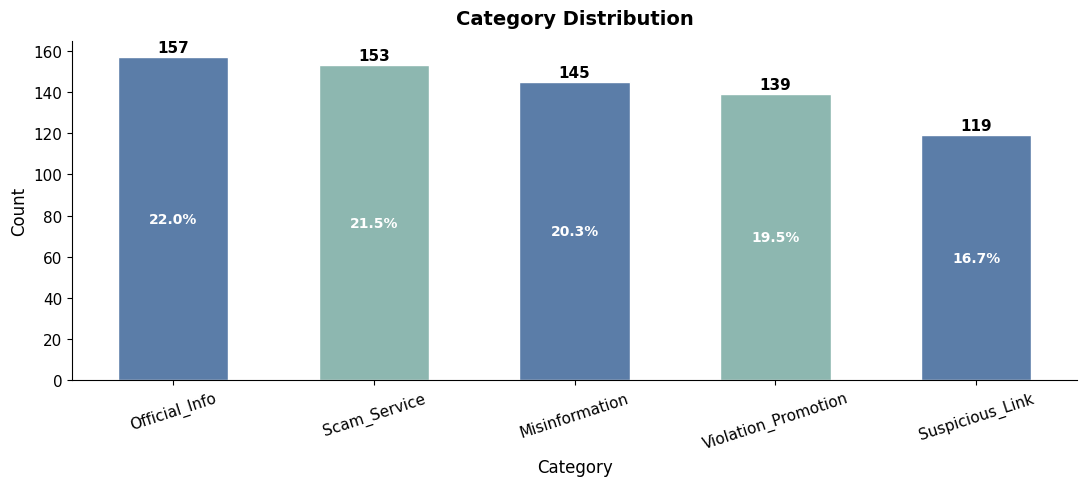


Category Counts:
category
Official_Info          157
Scam_Service           153
Misinformation         145
Violation_Promotion    139
Suspicious_Link        119

Total: 713

Observation: Categories are approximately balanced, making the dataset suitable for training without oversampling.


In [ ]:
cat_counts = df['category'].value_counts()


colors = [
    '#5B7DA8',  # blue
    '#8DB7B0',  # teal
    '#5B7DA8',  # blue
    '#8DB7B0',  # teal
    '#5B7DA8'   # blue
]

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    cat_counts.index,
    cat_counts.values,
    color=colors,
    width=0.55,
    edgecolor='white'
)

ax.set_title('Category Distribution', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Category', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='x', rotation=18)

total = cat_counts.sum()

for bar, val in zip(bars, cat_counts.values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(val),
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )


    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f'{val/total*100:.1f}%',
        ha='center',
        va='center',
        color='white',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig('plot_category.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nCategory Counts:")
print(cat_counts.to_string())

print(f"\nTotal: {total}")

print(
    "\nObservation: Categories are approximately balanced, "
    "making the dataset suitable for training without oversampling."
)

### 5.4 Risk Level Distribution

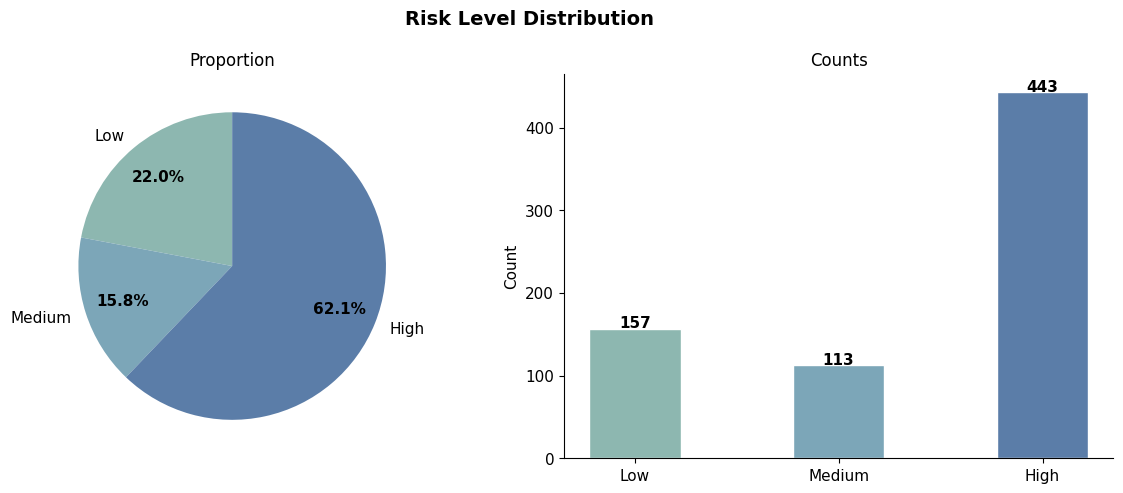

Risk Level Counts:
risk_level
Low       157
Medium    113
High      443


In [ ]:
risk_order = ['Low', 'Medium', 'High']
risk_counts = df['risk_level'].value_counts().reindex(risk_order, fill_value=0)


risk_colors = [
    '#8DB7B0',  # Low
    '#7CA6B8',  # Medium
    '#5B7DA8'   # High
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Risk Level Distribution', fontsize=14, fontweight='bold')

# Pie Chart
wedges, texts, autotexts = ax1.pie(
    risk_counts.values,
    labels=risk_counts.index,
    colors=risk_colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75
)

for t in autotexts:
    t.set_fontweight('bold')

ax1.set_title('Proportion', fontsize=12)

# Bar Chart
bars = ax2.bar(
    risk_counts.index,
    risk_counts.values,
    color=risk_colors,
    width=0.45,
    edgecolor='white'
)

ax2.set_title('Counts', fontsize=12)
ax2.set_ylabel('Count', fontsize=11)

for bar, val in zip(bars, risk_counts.values):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(val),
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig('plot_risk.png', dpi=150, bbox_inches='tight')
plt.show()

print("Risk Level Counts:")
print(risk_counts.to_string())

### 5.5 Language Distribution

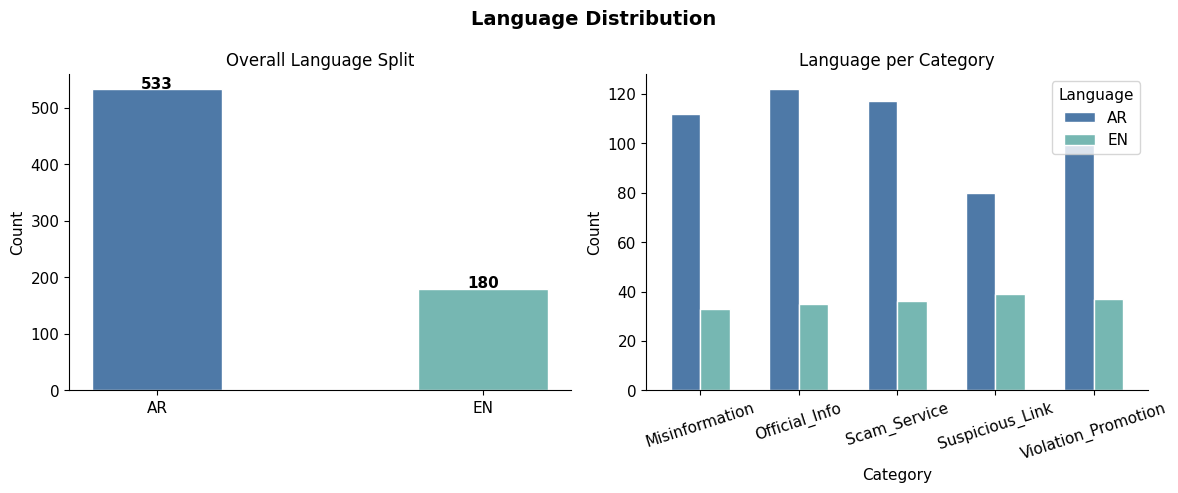

Language Counts:
language
AR    533
EN    180


In [ ]:
lang_counts = df['language'].value_counts()
lang_colors = ['#4E79A7', '#76B7B2', '#F28E2B']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Language Distribution', fontsize=14, fontweight='bold')

# Overall bar
bars = ax1.bar(lang_counts.index, lang_counts.values, color=lang_colors[:len(lang_counts)],
               width=0.4, edgecolor='white')
ax1.set_title('Overall Language Split', fontsize=12)
ax1.set_ylabel('Count', fontsize=11)
for bar, val in zip(bars, lang_counts.values):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
             str(val), ha='center', fontweight='bold')

# Per category
lang_cat = df.groupby(['category', 'language']).size().unstack(fill_value=0)
lang_cat.plot(kind='bar', ax=ax2, color=lang_colors[:len(lang_cat.columns)],
              width=0.6, edgecolor='white')
ax2.set_title('Language per Category', fontsize=12)
ax2.set_xlabel('Category', fontsize=11)
ax2.set_ylabel('Count', fontsize=11)
ax2.tick_params(axis='x', rotation=18)
ax2.legend(title='Language')

plt.tight_layout()
plt.savefig('plot_language.png', dpi=150, bbox_inches='tight')
plt.show()

print("Language Counts:")
print(lang_counts.to_string())

### 5.6 Source Type Distribution

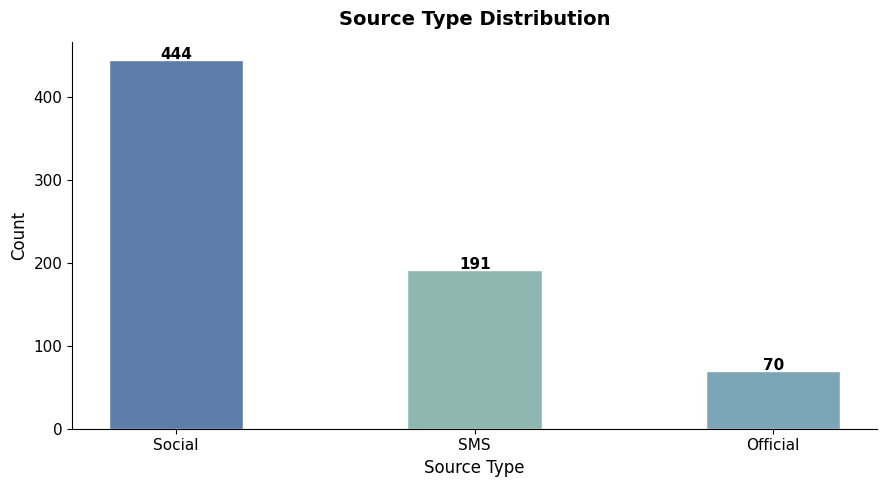

Source Type Counts:
source_type
Social      444
SMS         191
Official     70


In [ ]:
src_counts = df['source_type'].value_counts()

src_colors = [
    '#5B7DA8',
    '#8DB7B0',
    '#7CA6B8',
    '#9AC5BE'
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    src_counts.index,
    src_counts.values,
    color=src_colors[:len(src_counts)],
    width=0.45,
    edgecolor='white'
)

ax.set_title('Source Type Distribution', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Source Type', fontsize=12)
ax.set_ylabel('Count', fontsize=12)

for bar, val in zip(bars, src_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(val),
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig('plot_source.png', dpi=150, bbox_inches='tight')
plt.show()

print("Source Type Counts:")
print(src_counts.to_string())

### 5.7 Text Length Analysis

Text Length Statistics:
       text_length  word_count
count        713.0       713.0
mean          78.4        13.4
std           21.8         3.1
min           37.0         6.0
25%           62.0        11.0
50%           77.0        13.0
75%           92.0        15.0
max          156.0        25.0



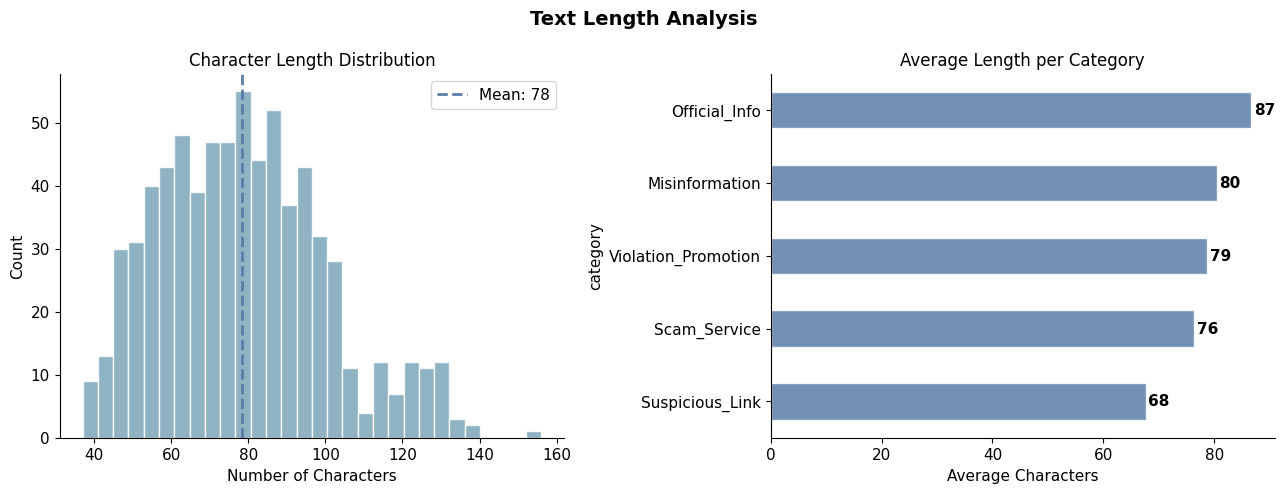

In [ ]:
df['text_length'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

print("Text Length Statistics:")
print(df[['text_length', 'word_count']].describe().round(1).to_string())
print()


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Text Length Analysis', fontsize=14, fontweight='bold')

# Character Length Distribution
axes[0].hist(
    df['text_length'],
    bins=30,
    color='#7CA6B8',
    edgecolor='white',
    alpha=0.85
)

axes[0].axvline(
    df['text_length'].mean(),
    color='#5B7DA8',
    linestyle='--',
    linewidth=2,
    label=f"Mean: {df['text_length'].mean():.0f}"
)

axes[0].set_title('Character Length Distribution', fontsize=12)
axes[0].set_xlabel('Number of Characters')
axes[0].set_ylabel('Count')
axes[0].legend()

# Average Length per Category
avg_len = df.groupby('category')['text_length'].mean().sort_values()

avg_len.plot(
    kind='barh',
    ax=axes[1],
    color='#5B7DA8',
    alpha=0.85,
    edgecolor='white'
)

axes[1].set_title('Average Length per Category', fontsize=12)
axes[1].set_xlabel('Average Characters')

for i, v in enumerate(avg_len.values):
    axes[1].text(
        v + 0.5,
        i,
        f'{v:.0f}',
        va='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig('plot_length.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Data Preprocessing



In [ ]:
# Step 1: Fill missing values in secondary columns
df['reason'].fillna('No specific reason provided', inplace=True)
df['recommended_action'].fillna('Verify through official channels', inplace=True)
df['source_type'].fillna('Unknown', inplace=True)


# Verify critical columns
print("Verification:")
for col in ['text', 'category', 'risk_level']:
    m = df[col].isnull().sum()
    print(f"  {col:<20} missing: {m}")

Verification:
  text                 missing: 0
  category             missing: 0
  risk_level           missing: 0


In [ ]:
def clean_text(text):

    text = str(text)

    # 1. Lowercase English characters
    text = text.lower()

    # 2. Replace suspicious links and URLs with token 'link'
    text = re.sub(r'\[suspicious-link\]', 'link', text)
    text = re.sub(r'example\[\.\]com', 'link', text)
    text = re.sub(r'https?://\S+|www\.\S+', 'link', text)

    # 3. Remove hashtag symbol — keep the word
    text = re.sub(r'#(\w+)', r'\1', text)

    # 4. Normalize Hamza (أ إ آ → ا)
    text = re.sub(r'[أإآ]', 'ا', text)

    # 5. Normalize Alef Maqsura (ي → ى)
    text = text.replace('ى', 'ي')

    # 6. Normalize و → ؤ and ي → ئ
    text = text.replace('ؤ', 'و')
    text = text.replace('ئ', 'ي')

    # 7. Remove Arabic Tashkeel (diacritics)
    text = re.sub(r'[\u064B-\u065F]', '', text)

    # 8. Remove excess punctuation and symbols
    #    Keep: Arabic chars, English chars, digits, spaces
    text = re.sub(r'[^\w\s\u0600-\u06FF0-9]', ' ', text)

    # 9. Clean extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Test the cleaning function
test_samples = [
    'نطلع لك تصريح حج مضمون خلال ساعه!! بـ 500 ريال',
    'لا حج بلا تصريح #لا_حج_بلا_تصريح',
    'جدد تصريحك الحين [suspicious-link]',
    'Hajj permit guaranteed in 24h!! DM now',
    'أداء الحج بدون تصريح مخالفة نظامية',
    'يعاقب بغرامة مالية تصل إلى 20000 ريال كل من يضبط مؤدياً أداء الحج دون تصريح',
]

print("Preprocessing Test — Before vs After")
print("-" * 65)
for sample in test_samples:
    cleaned = clean_text(sample)
    print(f"Before : {sample}")
    print(f"After  : {cleaned}")
    print()

Preprocessing Test — Before vs After
-----------------------------------------------------------------
Before : نطلع لك تصريح حج مضمون خلال ساعه!! بـ 500 ريال
After  : نطلع لك تصريح حج مضمون خلال ساعه بـ 500 ريال

Before : لا حج بلا تصريح #لا_حج_بلا_تصريح
After  : لا حج بلا تصريح لا_حج_بلا_تصريح

Before : جدد تصريحك الحين [suspicious-link]
After  : جدد تصريحك الحين link

Before : Hajj permit guaranteed in 24h!! DM now
After  : hajj permit guaranteed in 24h dm now

Before : أداء الحج بدون تصريح مخالفة نظامية
After  : اداء الحج بدون تصريح مخالفة نظامية

Before : يعاقب بغرامة مالية تصل إلى 20000 ريال كل من يضبط مؤدياً أداء الحج دون تصريح
After  : يعاقب بغرامة مالية تصل الي 20000 ريال كل من يضبط موديا اداء الحج دون تصريح



In [ ]:
# Apply cleaning to the full dataset
df['clean_text'] = df['text'].apply(clean_text)

print(f"Preprocessing applied to {len(df)} rows.")
print()
print("Sample comparison for 3 rows:")
for i in range(3):
    print(f"Before : {df['text'].iloc[i]}")
    print(f"After  : {df['clean_text'].iloc[i]}")
    print()

Preprocessing applied to 713 rows.

Sample comparison for 3 rows:
Before : يعاقب بغرامة مالية تصل إلى 20000 ريال كل من يضبط مؤدياً أو محاولاً أداء الحج دون تصريح. #لا_حج_بلا_تصريح
After  : يعاقب بغرامة مالية تصل الي 20000 ريال كل من يضبط موديا او محاولا اداء الحج دون تصريح لا_حج_بلا_تصريح

Before : تنبيه رسمي: يُرحَّل المتسللون للحج من المقيمين والمتخلفين ويُمنعون من دخول المملكة 10 سنوات. #لا_حج_بلا_تصريح
After  : تنبيه رسمي يرحل المتسللون للحج من المقيمين والمتخلفين ويمنعون من دخول المملكة 10 سنوات لا_حج_بلا_تصريح

Before : وزارة الحج والعمرة: التصريح شرط أساسي لأداء الحج تأكد من استخراجه عبر المنصات الرسمية المعتمدة
After  : وزارة الحج والعمرة التصريح شرط اساسي لاداء الحج تاكد من استخراجه عبر المنصات الرسمية المعتمدة



## 7. Train / Test Split

In [ ]:
X = df['clean_text']   # Features — cleaned text
y = df['category']     # Target  — category

print(f"Features (X) : {X.shape[0]} texts")
print(f"Target   (y) : {y.nunique()} categories")
print(f"Categories   : {list(y.unique())}")
print()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size    = 0.2,
    random_state = 42,
    stratify     = y
)

print("Train / Test Split (80% / 20%)")
print(f"  Training set : {len(X_train)} rows ({len(X_train)/len(X)*100:.0f}%)")
print(f"  Testing set  : {len(X_test)} rows ({len(X_test)/len(X)*100:.0f}%)")
print()
print("Category distribution in Training set:")
print(y_train.value_counts().to_string())
print()
print("Category distribution in Testing set:")
print(y_test.value_counts().to_string())

Features (X) : 713 texts
Target   (y) : 5 categories
Categories   : ['Official_Info', 'Scam_Service', 'Misinformation', 'Suspicious_Link', 'Violation_Promotion']

Train / Test Split (80% / 20%)
  Training set : 570 rows (80%)
  Testing set  : 143 rows (20%)

Category distribution in Training set:
category
Official_Info          126
Scam_Service           122
Misinformation         116
Violation_Promotion    111
Suspicious_Link         95

Category distribution in Testing set:
category
Scam_Service           31
Official_Info          31
Misinformation         29
Violation_Promotion    28
Suspicious_Link        24


## 8. SentenceTransformer Embeddings

We use `paraphrase-multilingual-mpnet-base-v2` — an upgraded multilingual model that:
- Supports **Arabic and English** natively
- Converts each message into a **768-dimensional dense vector**
- Captures **deeper semantic meaning** — better context understanding

In [ ]:
# Load the SentenceTransformer model

print("Loading SentenceTransformer model...")
print("Model: paraphrase-multilingual-mpnet-base-v2")
print()

embedder = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2')
print("Model loaded successfully.")
print()

# Convert training and testing sets to embeddings
print("Generating embeddings for training set...")
X_train_emb = embedder.encode(X_train.tolist(), show_progress_bar=True)

print("\nGenerating embeddings for testing set...")
X_test_emb  = embedder.encode(X_test.tolist(), show_progress_bar=True)

print()
print(f"Training embeddings shape : {X_train_emb.shape}")
print(f"Testing embeddings shape  : {X_test_emb.shape}")
print(f"Each message is represented by {X_train_emb.shape[1]} numbers (dimensions)")
print()

Loading SentenceTransformer model...
Model: paraphrase-multilingual-mpnet-base-v2



modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

Model loaded successfully.

Generating embeddings for training set...


Batches:   0%|          | 0/18 [00:00<?, ?it/s]


Generating embeddings for testing set...


Batches:   0%|          | 0/5 [00:00<?, ?it/s]


Training embeddings shape : (570, 768)
Testing embeddings shape  : (143, 768)
Each message is represented by 768 numbers (dimensions)



## 9. Model Training — Hyperparameter Tuning

We train and compare multiple configurations:
- **Logistic Regression** with different C values
- **LinearSVC (SVM)** with different C values

Goal: Find the configuration that achieves the highest Macro F1-Score.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Train all model variants

models_to_train = {
    'LR  C=1'  : LogisticRegression(max_iter=1000, C=1,   random_state=42),
    'LR  C=5'  : LogisticRegression(max_iter=1000, C=5,   random_state=42),
    'LR  C=10' : LogisticRegression(max_iter=1000, C=10,  random_state=42),
    'SVM C=0.5': LinearSVC(max_iter=3000,          C=0.5, random_state=42),
    'SVM C=1'  : LinearSVC(max_iter=3000,          C=1,   random_state=42),
    'SVM C=2'  : LinearSVC(max_iter=3000,          C=2,   random_state=42),
}

trained_models = {}
for name, model in models_to_train.items():
    print(f"Training {name}...")
    model.fit(X_train_emb, y_train)
    trained_models[name] = model

print("\nAll models trained successfully.")

Training LR  C=1...
Training LR  C=5...
Training LR  C=10...
Training SVM C=0.5...
Training SVM C=1...
Training SVM C=2...

All models trained successfully.


In [ ]:
# Evaluate all models

from sklearn.metrics import accuracy_score, f1_score

results = []

print(f"{'Model':<12} {'Accuracy':>10} {'Macro F1':>10}")
print("-" * 35)

for name, model in trained_models.items():
    y_pred   = model.predict(X_test_emb)
    acc      = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    results.append({'name': name, 'model': model, 'acc': acc, 'f1': macro_f1})
    print(f"  {name:<12} {acc:>10.4f} {macro_f1:>10.4f}")


print("\nBest model selected by Macro F1-Score")

Model          Accuracy   Macro F1
-----------------------------------
  LR  C=1          0.8671     0.8679
  LR  C=5          0.8881     0.8891
  LR  C=10         0.8811     0.8827
  SVM C=0.5        0.9231     0.9223
  SVM C=1          0.9161     0.9162
  SVM C=2          0.9091     0.9085

Best model selected by Macro F1-Score


In [ ]:
# Select best model

best = max(results, key=lambda x: x['f1'])

best_model      = best['model']
best_model_name = best['name']
best_f1         = best['f1']

print(f"Best Model  : {best_model_name}")
print(f"Accuracy    : {best['acc']:.4f}  ({best['acc']*100:.2f}%)")
print(f"Macro F1    : {best_f1:.4f}")

Best Model  : SVM C=0.5
Accuracy    : 0.9231  (92.31%)
Macro F1    : 0.9223


  Best Model: SVM C=0.5
  Accuracy       : 0.9231  (92.31%)
  Macro F1-Score : 0.9223

  Classification Report:
                     precision    recall  f1-score   support

     Misinformation       0.93      0.90      0.91        29
      Official_Info       0.91      1.00      0.95        31
       Scam_Service       0.88      0.90      0.89        31
    Suspicious_Link       1.00      0.83      0.91        24
Violation_Promotion       0.93      0.96      0.95        28

           accuracy                           0.92       143
          macro avg       0.93      0.92      0.92       143
       weighted avg       0.93      0.92      0.92       143



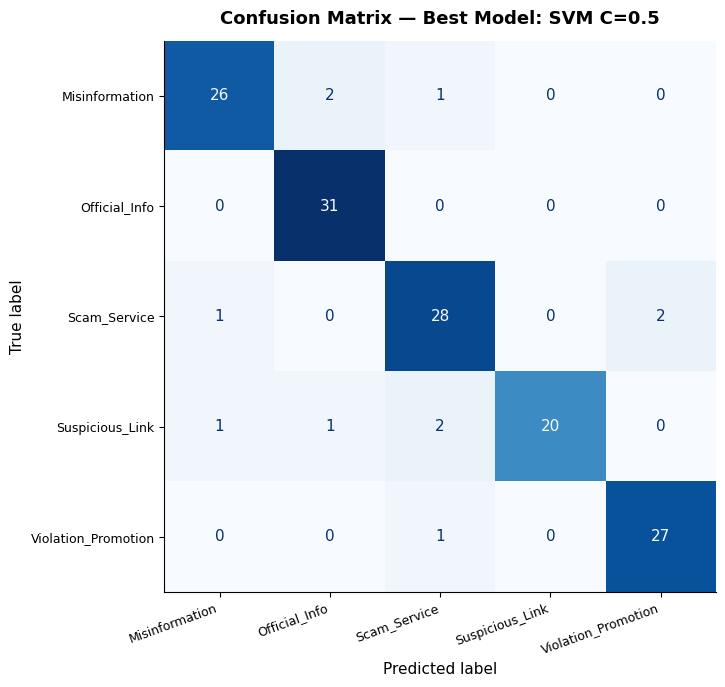

In [ ]:
# Full evaluation of best model

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_test_emb)

print(f"  Best Model: {best_model_name}")
print(f"  Accuracy       : {accuracy_score(y_test, y_pred):.4f}  ({accuracy_score(y_test, y_pred)*100:.2f}%)")
print(f"  Macro F1-Score : {f1_score(y_test, y_pred, average='macro'):.4f}")
print()
print("  Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
categories = sorted(y_test.unique())
cm         = confusion_matrix(y_test, y_pred, labels=categories)

fig, ax = plt.subplots(figsize=(9, 7))
disp    = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categories)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — Best Model: {best_model_name}',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xticklabels(categories, rotation=20, ha='right', fontsize=9)
ax.set_yticklabels(categories, fontsize=9)
plt.tight_layout()
plt.savefig('confusion_matrix_best.png', dpi=150, bbox_inches='tight')
plt.show()

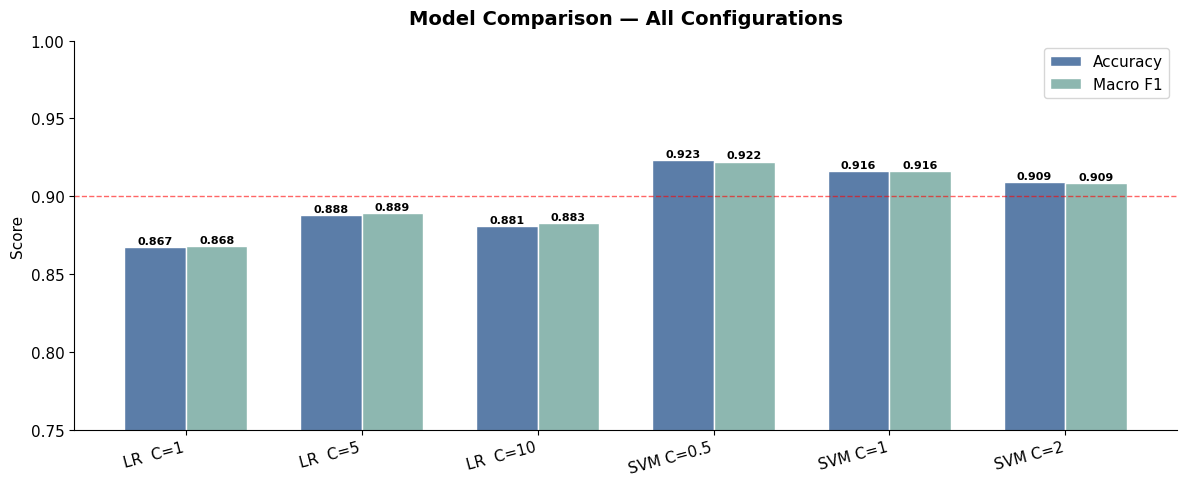

Best achieved: 92.31% accuracy / 0.9223 Macro F1


In [ ]:
# Compare all models — bar chart

import matplotlib.pyplot as plt
import numpy as np

names    = [r['name'] for r in results]
accs     = [r['acc']  for r in results]
f1s      = [r['f1']   for r in results]

x      = np.arange(len(names))
width  = 0.35
colors = ['#5B7DA8', '#8DB7B0']

fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, accs, width, label='Accuracy', color=colors[0], edgecolor='white')
bars2 = ax.bar(x + width/2, f1s,  width, label='Macro F1', color=colors[1], edgecolor='white')

ax.set_title('Model Comparison — All Configurations', fontsize=14, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=15, ha='right')
ax.set_ylim(0.75, 1.0)
ax.set_ylabel('Score')
ax.legend()
ax.axhline(0.90, color='red', linestyle='--', linewidth=1, alpha=0.6, label='90% target')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{bar.get_height():.3f}', ha='center', fontsize=8, fontweight='bold')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{bar.get_height():.3f}', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Best achieved: {max(accs)*100:.2f}% accuracy / {max(f1s):.4f} Macro F1")

In [ ]:
# Cross-Validation on best model

from sklearn.model_selection import cross_val_score

print(f"5-Fold Cross-Validation — {best_model_name}")

cv_scores = cross_val_score(
    best_model, X_train_emb, y_train,
    cv=5, scoring='f1_macro'
)

print(f"  Fold Scores : {[round(s, 4) for s in cv_scores]}")
print(f"  Mean F1     : {cv_scores.mean():.4f}")
print(f"  Std Dev     : {cv_scores.std():.4f}")
print()
print("  Low std deviation = model generalizes well across different data splits.")

5-Fold Cross-Validation — SVM C=0.5
  Fold Scores : [np.float64(0.9148), np.float64(0.9559), np.float64(0.9135), np.float64(0.881), np.float64(0.8578)]
  Mean F1     : 0.9046
  Std Dev     : 0.0334

  Low std deviation = model generalizes well across different data splits.


## 12. Risk Level and Recommendation Mapping

After classification, we apply **rule-based mapping** to assign:
- `risk_level` — based on category
- `recommended_action` — actionable guidance for the user

This is deterministic and requires no training.

### 12.1 Reason Mapping

In [ ]:
# Reason mapping — Arabic and English
reason_map = {
    'Official_Info': {
        'ar': 'هذه الرسالة من جهة حكومية رسمية وتحتوي على معلومات صحيحة عن تصاريح الحج.',
        'en': 'This message is from an official government source providing accurate information about Hajj permits.'
    },
    'Misinformation': {
        'ar': 'هذه الرسالة تحتوي على معلومات خاطئة أو مضللة عن أنظمة الحج.',
        'en': 'This message contains false or unverified information that may mislead people about Hajj regulations.'
    },
    'Scam_Service': {
        'ar': 'هذه الرسالة تعرض خدمة احتيالية تدّعي إصدار تصاريح حج خارج القنوات الرسمية.',
        'en': 'This message offers a fraudulent service claiming to issue official Hajj permits outside authorized channels.'
    },
    'Violation_Promotion': {
        'ar': 'هذه الرسالة تروّج لمخالفة أنظمة تصاريح الحج أو تسهّلها.',
        'en': 'This message promotes or facilitates violation of Hajj permit regulations.'
    },
    'Suspicious_Link': {
        'ar': 'هذه الرسالة تحتوي على رابط مشبوه أو طلب دفع ينتحل صفة جهة رسمية.',
        'en': 'This message contains a suspicious link or payment request impersonating an official platform.'
    }
}

print("Reason Mapping:")
for cat, reason in reason_map.items():
    print(f"  {cat:<25}")
    print(f"    AR: {reason['ar']}")
    print(f"    EN: {reason['en']}")
    print()


Reason Mapping:
  Official_Info            
    AR: هذه الرسالة من جهة حكومية رسمية وتحتوي على معلومات صحيحة عن تصاريح الحج.
    EN: This message is from an official government source providing accurate information about Hajj permits.

  Misinformation           
    AR: هذه الرسالة تحتوي على معلومات خاطئة أو مضللة عن أنظمة الحج.
    EN: This message contains false or unverified information that may mislead people about Hajj regulations.

  Scam_Service             
    AR: هذه الرسالة تعرض خدمة احتيالية تدّعي إصدار تصاريح حج خارج القنوات الرسمية.
    EN: This message offers a fraudulent service claiming to issue official Hajj permits outside authorized channels.

  Violation_Promotion      
    AR: هذه الرسالة تروّج لمخالفة أنظمة تصاريح الحج أو تسهّلها.
    EN: This message promotes or facilitates violation of Hajj permit regulations.

  Suspicious_Link          
    AR: هذه الرسالة تحتوي على رابط مشبوه أو طلب دفع ينتحل صفة جهة رسمية.
    EN: This message contains a suspicious link or

In [ ]:
# Risk Level mapping — Arabic and English
risk_map = {
    'Official_Info': {
        'ar': 'منخفض',
        'en': 'Low'
    },
    'Misinformation': {
        'ar': 'متوسط',
        'en': 'Medium'
    },
    'Scam_Service': {
        'ar': 'مرتفع',
        'en': 'High'
    },
    'Violation_Promotion': {
        'ar': 'مرتفع',
        'en': 'High'
    },
    'Suspicious_Link': {
        'ar': 'مرتفع',
        'en': 'High'
    }
}

# Internal fixed risk keys — used for code logic and API filtering
# This key does NOT change based on UI language.
risk_key_map = {
    'Official_Info': 'low',
    'Misinformation': 'medium',
    'Scam_Service': 'high',
    'Violation_Promotion': 'high',
    'Suspicious_Link': 'high'
}

# Recommended Action mapping — displayed to the user only
# Important: recommended_action is NOT sent to the authority report.
action_map = {
    'Official_Info': {
        'ar': 'أمورك تمام! هذه الرسالة رسمية وصادرة من جهة حكومية.',
        'en': 'You are good! This message is official and issued by a government authority.'
    },
    'Misinformation': {
        'ar': 'لا تعتمد على هذه الرسالة، وتحقق من المعلومات عبر قنوات الحج الرسمية.',
        'en': 'Do not rely on this message; verify the information through official Hajj channels.'
    },
    'Scam_Service': {
        'ar': 'لا تدفع ولا تشارك بياناتك الشخصية، وبلّغ عن الخدمات المشبوهة.',
        'en': 'Do not pay or share personal data; report suspicious services.'
    },
    'Violation_Promotion': {
        'ar': 'لا تتفاعل مع المحتوى الذي يروّج لمخالفة الأنظمة.',
        'en': 'Do not engage with content that promotes violating regulations.'
    },
    'Suspicious_Link': {
        'ar': 'لا تفتح الرابط، واستخدم المنصات الرسمية فقط.',
        'en': 'Do not open the link; use official platforms only.'
    }
}

print("Risk Level Mapping:")
for cat, risk in risk_map.items():
    print(f"  {cat:<25}")
    print(f"    AR : {risk['ar']}")
    print(f"    EN : {risk['en']}")
    print(f"    KEY: {risk_key_map[cat]}")
    print()

print("Recommended Action Mapping — User-facing only:")
for cat, action in action_map.items():
    print(f"  {cat:<25}")
    print(f"    AR: {action['ar']}")
    print(f"    EN: {action['en']}")
    print()


Risk Level Mapping:
  Official_Info            
    AR : منخفض
    EN : Low
    KEY: low

  Misinformation           
    AR : متوسط
    EN : Medium
    KEY: medium

  Scam_Service             
    AR : مرتفع
    EN : High
    KEY: high

  Violation_Promotion      
    AR : مرتفع
    EN : High
    KEY: high

  Suspicious_Link          
    AR : مرتفع
    EN : High
    KEY: high

Recommended Action Mapping — User-facing only:
  Official_Info            
    AR: أمورك تمام! هذه الرسالة رسمية وصادرة من جهة حكومية.
    EN: You are good! This message is official and issued by a government authority.

  Misinformation           
    AR: لا تعتمد على هذه الرسالة، وتحقق من المعلومات عبر قنوات الحج الرسمية.
    EN: Do not rely on this message; verify the information through official Hajj channels.

  Scam_Service             
    AR: لا تدفع ولا تشارك بياناتك الشخصية، وبلّغ عن الخدمات المشبوهة.
    EN: Do not pay or share personal data; report suspicious services.

  Violation_Promotion      
 

## 13. Prediction Function

The `predict_message()` function takes any message as input and returns:
- **Category** — classified by the best model
- **Risk Level** — from rule-based mapping
- **Recommended Action** — from rule-based mapping

In [ ]:
def detect_language(text):
    """
    Detects the output language for single-language input.
    - If the message contains English letters only, return 'en'.
    - If the message contains Arabic letters only, return 'ar'.
    - If the message has no Arabic or English letters, default to 'ar'.
    """
    text = str(text)
    arabic_chars = re.findall(r'[\u0600-\u06FF]', text)
    english_chars = re.findall(r'[A-Za-z]', text)

    if len(english_chars) > 0 and len(arabic_chars) == 0:
        return 'en'
    return 'ar'


def validate_single_language(text):
    """
    Blocks mixed Arabic + English input before prediction.
    Numbers, punctuation, emojis, links, and spaces do not count as a language.
    """
    text = str(text)
    has_arabic = bool(re.search(r'[\u0600-\u06FF]', text))
    has_english = bool(re.search(r'[A-Za-z]', text))

    if has_arabic and has_english:
        return {
            'is_valid': False,
            'language': 'mixed',
            'error_ar': 'لا يمكنك إدخال أكثر من لغة. يجب عليك إدخال النص بلغة واحدة فقط.',
            'error_en': 'You cannot enter more than one language. Please enter the text in only one language.'
        }

    return {
        'is_valid': True,
        'language': detect_language(text),
        'error_ar': None,
        'error_en': None
    }


def predict_message(message, lang=None):
    """
    Predicts the message category and returns risk, reason, and action
    in the same language as the user input.

    Report button logic:
    - Official_Info -> no report button
    - Medium / High risk -> show report button
    - Low risk -> no report button
    """
    validation = validate_single_language(message)

    if not validation['is_valid']:
        return {
            'status': 'error',
            'category': None,
            'risk_level': None,
            'risk_level_key': None,
            'reason': None,
            'recommended_action': None,
            'show_report_button': False,
            'language': 'mixed',
            'error_ar': validation['error_ar'],
            'error_en': validation['error_en']
        }

    if lang is None:
        lang = validation['language']

    cleaned = clean_text(message)
    embedding = embedder.encode([cleaned])
    category = best_model.predict(embedding)[0]

    risk = risk_map[category][lang]
    risk_key = risk_key_map[category]
    reason = reason_map[category][lang]
    action = action_map[category][lang]

    # UI/report eligibility logic should use the stable key, not the translated text.
    show_report_button = category != 'Official_Info' and risk_key in ['medium', 'high']

    print("=" * 60)
    print("  HajjSafe AI — Message Analysis")
    print("=" * 60)
    print(f"  Language           : {lang}")
    print(f"  Category           : {category}")
    print(f"  Risk Level         : {risk}")
    print(f"  Risk Key           : {risk_key}")
    print(f"  Reason             : {reason}")
    print(f"  Recommended Action : {action}")
    print(f"  Show Report Button : {show_report_button}")
    print("=" * 60)

    return {
        'status': 'success',
        'category': category,
        'risk_level': risk,
        'risk_level_key': risk_key,
        'reason': reason,
        'recommended_action': action,   # User-facing only
        'show_report_button': show_report_button,
        'language': lang
    }


In [ ]:
from datetime import datetime
import pandas as pd
import requests

class ReportManager:
    """
    Handles structured reports for suspicious Hajj messages.

    User-facing recommended_action is intentionally NOT included in the authority report,
    because it is guidance for pilgrims, not investigation data for authorities.
    """

    VALID_SOURCES = [
        "SMS",
        "WhatsApp",
        "Social Media",
        "Email",
        "Phone Call",
        "Other"
    ]

    def __init__(
        self,
        api_url="https://example-authority-api.com/reports",
        file_name="reports_backup.csv",
        enable_api=True,
        save_backup=True
    ):
        self.api_url = api_url
        self.file_name = file_name
        self.enable_api = enable_api
        self.save_backup = save_backup

    def validate_report_input(self, source, sender_info):
        if source not in self.VALID_SOURCES:
            raise ValueError(f"Source must be one of {self.VALID_SOURCES}")

        if source == "Social Media" and not sender_info:
            raise ValueError("Account name or link is required for Social Media reports.")

        if source == "WhatsApp" and not sender_info:
            raise ValueError("Phone number is required for WhatsApp reports.")

        if source == "SMS" and not sender_info:
            raise ValueError("Phone number or sender name is required for SMS reports.")

        if source == "Email" and not sender_info:
            raise ValueError("Email address is required for Email reports.")

        if source == "Phone Call" and not sender_info:
            raise ValueError("Caller phone number is required.")

    def build_report_payload(self, message, source, sender_info, prediction_result, notes=""):
        """
        Builds the API payload sent to the concerned authority.
        This payload is internal and should not be displayed to the user in Streamlit.
        """
        self.validate_report_input(source, sender_info)

        if prediction_result.get("status") != "success":
            raise ValueError("Cannot submit a report for an invalid or failed prediction.")

        category = prediction_result["category"]
        risk_key = prediction_result["risk_level_key"]

        # Official / low-risk messages should never be reported.
        if category == "Official_Info" or risk_key == "low":
            raise ValueError("This message is official or low risk and is not eligible for reporting.")

        report_payload = {
            "timestamp": datetime.now().isoformat(),
            "message": message,
            "source": source,
            "sender_info": sender_info,
            "category": category,
            "risk_level": prediction_result["risk_level"],
            "risk_level_key": risk_key,
            "reason": prediction_result["reason"],
            "language": prediction_result["language"],
            "notes": notes
        }

        return report_payload

    def send_to_authority_api(self, report_payload):
        """
        Sends the structured report to the concerned authority API.
        Replace api_url with the official endpoint when available.
        """
        if not self.enable_api:
            return {
                "success": True,
                "mode": "api_disabled",
                "message": "API sending is disabled. Report prepared successfully."
            }

        try:
            response = requests.post(
                self.api_url,
                json=report_payload,
                timeout=10
            )

            if response.status_code in [200, 201, 202]:
                return {
                    "success": True,
                    "mode": "api",
                    "message": "Report sent to authority API successfully.",
                    "status_code": response.status_code
                }

            return {
                "success": False,
                "mode": "api",
                "message": f"Authority API returned status code {response.status_code}.",
                "status_code": response.status_code
            }

        except Exception as e:
            return {
                "success": False,
                "mode": "api",
                "message": str(e)
            }

    def save_local_backup(self, report_payload):
        """Optional backup for demo/testing if the official API is not available."""
        try:
            df = pd.read_csv(self.file_name)
            df = pd.concat([df, pd.DataFrame([report_payload])], ignore_index=True)
        except FileNotFoundError:
            df = pd.DataFrame([report_payload])

        df.to_csv(self.file_name, index=False)

    def submit_report(self, message, source, sender_info, prediction_result, notes=""):
        """
        Main function used by the frontend when the user clicks Submit Report.
        It returns only success/failure status for the UI.
        Do not display the full payload in Streamlit.
        """
        report_payload = self.build_report_payload(
            message=message,
            source=source,
            sender_info=sender_info,
            prediction_result=prediction_result,
            notes=notes
        )

        api_result = self.send_to_authority_api(report_payload)

        if self.save_backup:
            self.save_local_backup(report_payload)

        # Return a UI-safe response only.
        return {
            "success": api_result["success"],
            "message": api_result["message"],
            "mode": api_result.get("mode", "api")
        }


## 14. Save Model

In [ ]:
import joblib
import os

os.makedirs('models', exist_ok=True)

# Save best model
joblib.dump(best_model, 'models/best_model.pkl')

# Save all mappings
joblib.dump(risk_map,   'models/risk_map.pkl')
joblib.dump(reason_map, 'models/reason_map.pkl')
joblib.dump(action_map, 'models/action_map.pkl')
joblib.dump(risk_key_map, 'models/risk_key_map.pkl')

print("Models saved successfully.")
print()
print(f"  best_model.pkl  — {best_model_name}")
print(f"  risk_map.pkl    — rule-based risk level mapping")
print(f"  reason_map.pkl  — Arabic + English reason mapping")
print(f"  action_map.pkl  — Arabic + English action mapping")
print(f"  risk_key_map.pkl — stable internal risk keys for logic/API")
print()
print("Note: SentenceTransformer is loaded directly from HuggingFace in the app.")
print("      No need to save it locally.")
print()

# Download models from Colab
from google.colab import files
import zipfile

# Zip models folder
with zipfile.ZipFile('models.zip', 'w') as zf:
    for fname in os.listdir('models'):
        zf.write(f'models/{fname}')

files.download('models.zip')
print("models.zip downloaded.")

Models saved successfully.

  best_model.pkl  — SVM C=0.5
  risk_map.pkl    — rule-based risk level mapping
  reason_map.pkl  — Arabic + English reason mapping
  action_map.pkl  — Arabic + English action mapping
  risk_key_map.pkl — stable internal risk keys for logic/API

Note: SentenceTransformer is loaded directly from HuggingFace in the app.
      No need to save it locally.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

models.zip downloaded.


#Manual Test

In [ ]:
test_messages = [
    # Arabic-only input -> Arabic output + report eligible if risky
    "نطلع لك تصريح حج مضمون بـ 500 ريال",

    # English-only input -> English output + report eligible if risky
    "Get your Hajj permit now for 500 SAR",

    # Mixed Arabic + English input -> blocked before prediction
    "نطلع لك Hajj permit مضمون خلال ساعة",

    # Arabic official-style input -> no report button
    "لا حج بلا تصريح والكل مسؤول عن نفسه"
]

for msg in test_messages:
    result = predict_message(msg)
    print(result)
    print()

# Example: authority report submission payload is built and sent internally.
# The full report is NOT shown in the Streamlit UI; only success/failure should be displayed.
report_manager = ReportManager(
    api_url="https://example-authority-api.com/reports",  # replace with official API endpoint later
    enable_api=False,  # keep False for demo until real endpoint is available
    save_backup=True
)

message = "نطلع لك تصريح حج مضمون بـ 500 ريال"
prediction_result = predict_message(message)

if prediction_result.get("show_report_button"):
    ui_response = report_manager.submit_report(
        message=message,
        source="WhatsApp",
        sender_info="+966500000000",
        prediction_result=prediction_result,
        notes="Demo report"
    )

    # UI-safe output only. Do not print/st.write the full report payload.
    print(ui_response)


  HajjSafe AI — Message Analysis
  Language           : ar
  Category           : Scam_Service
  Risk Level         : مرتفع
  Risk Key           : high
  Reason             : هذه الرسالة تعرض خدمة احتيالية تدّعي إصدار تصاريح حج خارج القنوات الرسمية.
  Recommended Action : لا تدفع ولا تشارك بياناتك الشخصية، وبلّغ عن الخدمات المشبوهة.
  Show Report Button : True
{'status': 'success', 'category': 'Scam_Service', 'risk_level': 'مرتفع', 'risk_level_key': 'high', 'reason': 'هذه الرسالة تعرض خدمة احتيالية تدّعي إصدار تصاريح حج خارج القنوات الرسمية.', 'recommended_action': 'لا تدفع ولا تشارك بياناتك الشخصية، وبلّغ عن الخدمات المشبوهة.', 'show_report_button': True, 'language': 'ar'}

  HajjSafe AI — Message Analysis
  Language           : en
  Category           : Scam_Service
  Risk Level         : High
  Risk Key           : high
  Reason             : This message offers a fraudulent service claiming to issue official Hajj permits outside authorized channels.
  Recommended Action : Do not pa